# 03 - Isolation Forest evaluation (Day 9)

**Question:** how well does an Isolation Forest on the engineered feature vectors (Day 6) detect
the simulated warehouse anomalies, how much does tuning help, does the streaming reservoir refit
beat a model frozen after warm-up, and how does it compare with the Day 8 statistical baseline?

Protocol (strictly chronological, nothing is tuned on the test period):

| Segment | Period (UTC) | Used for |
|---|---|---|
| cold start | 21:45 - 22:00 | discarded (aggregator windows not yet filled) |
| **warm-up / train** | 22:00 - 23:00 | initial fit (one hour, as specified) |
| **validation** | 23:00 - 01:30 | Optuna tuning, stacking-preview fit |
| **test** | 01:30 - 05:30 | all reported numbers |

Contextual anomalies are only injected 00:00 - 05:00, so the warm-up hour contains none: the
model must catch them without ever having seen one, which is the realistic situation.

In [1]:
import sys, os, time, json, logging, warnings
from pathlib import Path
from datetime import datetime, UTC, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, confusion_matrix)
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
logging.getLogger("src").setLevel(logging.WARNING)      # silence per-refit INFO logs
warnings.filterwarnings("ignore")

from src.models.offline_dataset import simulate_labeled_features
from src.models.isolation_forest_detector import (
    IsolationForestDetector, HyperparameterTuner, IsolationForestExplainer, binary_f1)
from src.models.model_registry import ModelRegistry
from src.models.statistical_detector import UnifiedStatisticalDetector

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
PAL = sns.color_palette("colorblind")
TYPES = ["point", "contextual", "collective"]
T = lambda day, h, m=0: datetime(2026, 11, day, h, m, tzinfo=UTC)
SEED = 7

## 1. Data: the production feature path, run offline

In [2]:
t0 = time.time()
ds = simulate_labeled_features(7.75 * 3600, start_time=T(20, 21, 45), seed=SEED)["warehouse"]
print(f"{len(ds):,} warehouse events -> feature vectors in {time.time()-t0:.0f}s "
      f"({len(ds)/(time.time()-t0):,.0f}/s), {len(ds.feature_names)} features, "
      f"{len(set(ds.entity_ids))} sensors")

SEG = {"warm-up (train)": (T(20, 22), T(20, 23)),
       "validation": (T(20, 23), T(21, 1, 30)),
       "test": (T(21, 1, 30), T(21, 5, 30))}
tr, va, te = (ds.subset(ds.between(*SEG[k]) & ds.warm) for k in SEG)
rows = []
for name, part in zip(SEG, (tr, va, te)):
    c = part.type_counts()
    rows.append(dict(segment=name, rows=len(part), anomaly_rate=part.anomaly_rate,
                     **{k: c.get(k, 0) for k in TYPES}))
pd.DataFrame(rows).set_index("segment").round(4)

334,800 warehouse events -> feature vectors in 34s (9,710/s), 30 features, 12 sensors


,rows,anomaly_rate,point,contextual,collective
segment,,,,,
warm-up (train),43200,0.0251,849,0,234
validation,108000,0.0498,2024,2853,503
test,172800,0.0634,3351,6786,824


In [3]:
print("Features:", ", ".join(ds.feature_names))

Features: value__last, value__mean_short, value__std_short, value__range_short, value__p95_short, value__roc_short, value__roc_medium, value__accel, value__level_shift, value__vol_ratio, value__z_window, value__z_baseline, value__dev_signed, time_since_last_anomaly_log, warmup_ratio, log_count_short, hour_sin, hour_cos, dow_sin, dow_cos, minute_sin, minute_cos, value__margin_low, value__margin_high, sensor_age_days, zone_A, zone_B, zone_C, anomaly_rate_7d, reliability


## 2. Defaults first

Config defaults (200 trees, `contamination=0.01`), fit on the warm-up hour. The detector trains on
a uniform sample of at most `reservoir_size` = 5 000 rows, the same amount the streaming refits use.

In [4]:
def eval_part(part, score, flag):
    """Per anomaly type: normals + that type only (as in notebook 02); ALL = every row."""
    rows = []
    for typ in TYPES + ["ALL"]:
        m = np.ones(len(part), bool) if typ == "ALL" else (~part.y | (part.anomaly_type == typ))
        y = part.y[m] if typ == "ALL" else (part.anomaly_type[m] == typ)
        rows.append(dict(type=typ, n_pos=int(y.sum()),
                         precision=precision_score(y, flag[m], zero_division=0),
                         recall=recall_score(y, flag[m], zero_division=0),
                         f1=f1_score(y, flag[m], zero_division=0),
                         auc_roc=roc_auc_score(y, score[m]), auc_pr=average_precision_score(y, score[m])))
    return pd.DataFrame(rows).set_index("type")

det0 = IsolationForestDetector(ds.feature_names).fit(tr.X)
s0, f0 = det0.score_batch(te.X), det0.predict(te.X)
print(f"default model flags {f0.mean():.2%} of test rows; true anomaly rate {te.anomaly_rate:.2%}")
eval_part(te, s0, f0).round(3)

default model flags 1.61% of test rows; true anomaly rate 6.34%


,n_pos,precision,recall,f1,auc_roc,auc_pr
type,,,,,,
point,3351,0.909,0.735,0.813,0.998,0.927
contextual,6786,0.118,0.005,0.009,0.741,0.111
collective,824,0.140,0.049,0.072,0.742,0.044
ALL,10961,0.912,0.231,0.369,0.820,0.479


## 3. Hyperparameter tuning with Optuna

50 trials, TPE sampler, `MedianPruner`; objective = pooled binary F1 on the **validation** period.
The default configuration is enqueued as trial 0, so tuning can only match or beat it on validation.
Tuning fits on a 5 000-row uniform sample of the warm-up hour.

In [5]:
rng = np.random.default_rng(0)
Xtr_sample = tr.X[np.sort(rng.choice(len(tr), 5000, replace=False))]
tuner = HyperparameterTuner(Xtr_sample, va.X, va.y, source_type="warehouse", n_trials=50, n_chunks=5)
t0 = time.time(); result = tuner.tune(); tune_s = time.time() - t0
print(f"{result.n_trials} trials ({result.n_complete} complete, {result.n_pruned} pruned) in {tune_s:.0f}s")
print(f"validation F1: default {result.default_f1:.3f} -> tuned {result.best_f1:.3f}")
print(json.dumps(result.best_params, indent=2))

50 trials (22 complete, 28 pruned) in 71s
validation F1: default 0.386 -> tuned 0.478
{
  "n_estimators": 201,
  "contamination": 0.019446974929547375,
  "max_features": 0.7315569330480514,
  "max_samples": 0.6409454518345838
}


In [6]:
path = tuner.save_best_params(ROOT / "configs" / "isolation_forest_best_params.json",
    extra={"data": "simulated warehouse sensors, seed 7; warm-up 22:00-23:00, validation 23:00-01:30 UTC",
           "notebook": "notebooks/03_isolation_forest_eval.ipynb"})
print("saved ->", path.relative_to(ROOT))

saved -> configs/isolation_forest_best_params.json


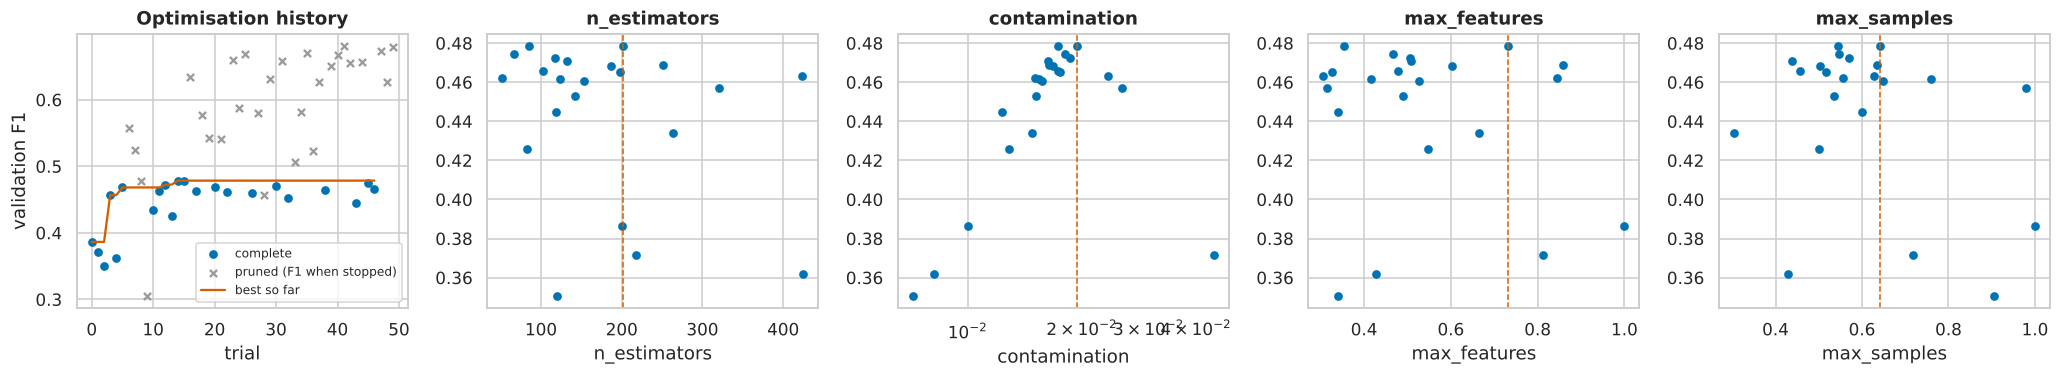

Parameter importance (fANOVA): {'contamination': 0.714, 'max_samples': 0.2, 'n_estimators': 0.056, 'max_features': 0.03}


In [7]:
import optuna
study = result.study
df = study.trials_dataframe()
done = df[df.state == "COMPLETE"]; pruned = df[df.state == "PRUNED"]
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
ax = axes[0]
ax.scatter(done.number, done.value, s=22, color=PAL[0], label="complete")
last_f1 = [list(study.trials[i].intermediate_values.values())[-1] for i in pruned.number]
ax.scatter(pruned.number, last_f1, s=22, color="0.6", marker="x", label="pruned (F1 when stopped)")
ax.plot(done.number, done.value.cummax(), color=PAL[3], lw=1.5, label="best so far")
ax.set_title("Optimisation history"); ax.set_xlabel("trial"); ax.set_ylabel("validation F1"); ax.legend(fontsize=8)
for ax, p in zip(axes[1:], ["n_estimators", "contamination", "max_features", "max_samples"]):
    ax.scatter(done[f"params_{p}"], done.value, s=22, color=PAL[0])
    ax.axvline(result.best_params[p], color=PAL[3], ls="--", lw=1)
    ax.set_title(p); ax.set_xlabel(p)
    if p == "contamination": ax.set_xscale("log")
plt.tight_layout(); plt.show()
imp = optuna.importance.get_param_importances(study)
print("Parameter importance (fANOVA):", {k: round(v, 3) for k, v in imp.items()})

## 4. Held-out test: default vs tuned

Same warm-up-only fit, evaluated on the untouched test period (01:30 - 05:30).

In [8]:
BEST = result.best_params
det_t = IsolationForestDetector(ds.feature_names, **BEST).fit(tr.X)
st, ft = det_t.score_batch(te.X), det_t.predict(te.X)
M0, Mt = eval_part(te, s0, f0), eval_part(te, st, ft)
cmp = pd.concat({"default": M0, "tuned": Mt}, names=["config"]).reset_index()
print(f"tuned model flags {ft.mean():.2%} of test rows (true rate {te.anomaly_rate:.2%})")
cmp.pivot(index="config", columns="type", values="f1").reindex(columns=TYPES + ["ALL"]).round(3)

tuned model flags 3.01% of test rows (true rate 6.34%)


type,point,contextual,collective,ALL
config,,,,
default,0.813,0.009,0.072,0.369
tuned,0.799,0.059,0.100,0.451


In [9]:
Mt

,n_pos,precision,recall,f1,auc_roc,auc_pr
type,,,,,,
point,3351,0.676831,0.973739,0.798581,0.998478,0.931194
contextual,6786,0.140177,0.037430,0.059084,0.750184,0.114532
collective,824,0.074272,0.151699,0.099721,0.743910,0.040293
ALL,10961,0.700385,0.332269,0.450715,0.825621,0.483982


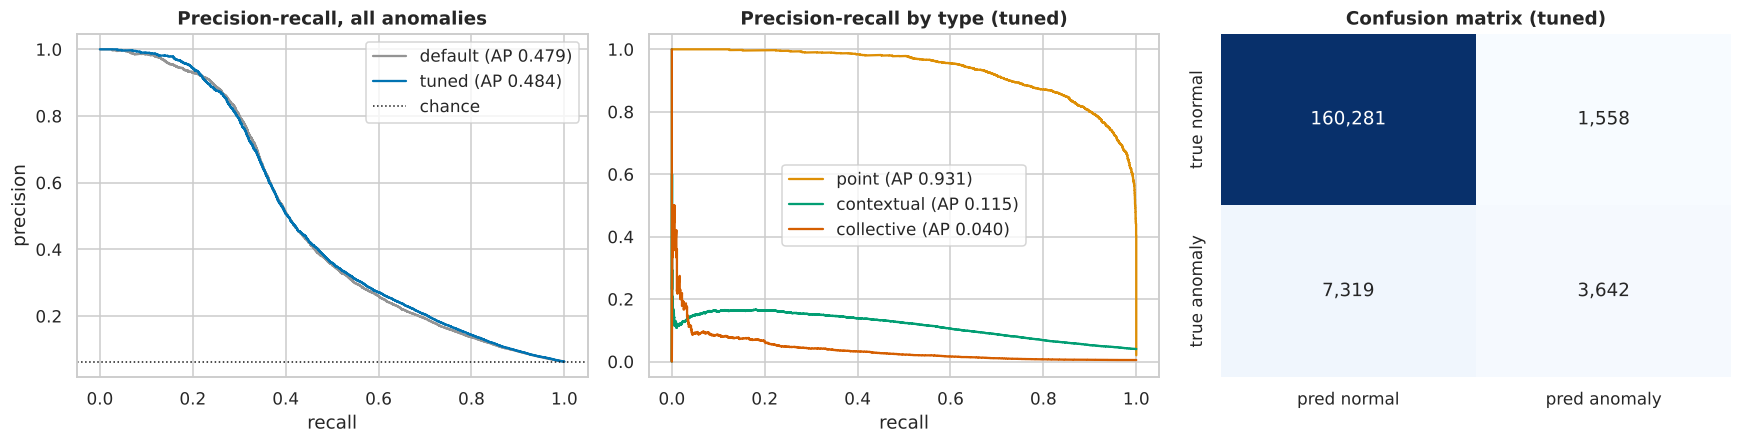

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
for nm, sc, c in [("default", s0, PAL[7]), ("tuned", st, PAL[0])]:
    p, r, _ = precision_recall_curve(te.y, sc)
    ax.plot(r, p, color=c, label=f"{nm} (AP {average_precision_score(te.y, sc):.3f})")
ax.axhline(te.anomaly_rate, color="k", ls=":", lw=1, label="chance")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall, all anomalies"); ax.legend()
ax = axes[1]
for typ, c in zip(TYPES, PAL[1:4]):
    m = ~te.y | (te.anomaly_type == typ); y = te.anomaly_type[m] == typ
    p, r, _ = precision_recall_curve(y, st[m])
    ax.plot(r, p, color=c, label=f"{typ} (AP {average_precision_score(y, st[m]):.3f})")
ax.set_xlabel("recall"); ax.set_title("Precision-recall by type (tuned)"); ax.legend()
ax = axes[2]
cm = confusion_matrix(te.y, ft, labels=[False, True])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["pred normal", "pred anomaly"], yticklabels=["true normal", "true anomaly"])
ax.set_title("Confusion matrix (tuned)")
plt.tight_layout(); plt.show()

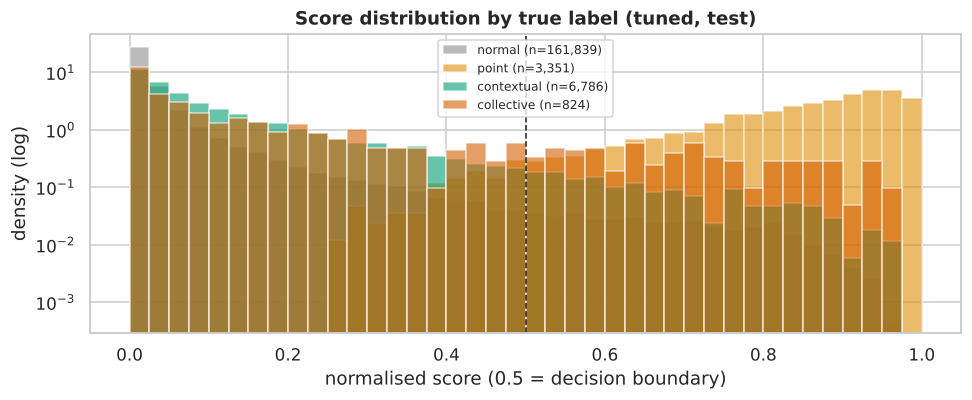

In [11]:
pal = dict(zip(["normal"] + TYPES, ["0.55"] + PAL[1:4]))
labels = np.where(te.y, te.anomaly_type.astype(str), "normal")
fig, ax = plt.subplots(figsize=(9, 3.8))
for lab in ["normal"] + TYPES:
    s = st[labels == lab]
    ax.hist(s, bins=np.linspace(0, 1, 41), density=True, alpha=0.6, color=pal[lab], label=f"{lab} (n={len(s):,})")
ax.axvline(0.5, color="k", ls="--", lw=1); ax.set_yscale("log")
ax.set_xlabel("normalised score (0.5 = decision boundary)"); ax.set_ylabel("density (log)")
ax.set_title("Score distribution by true label (tuned, test)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Event-level view: does it catch each anomaly episode, and how fast?

Row-wise F1 rewards long episodes. An operator cares about *"was the incident detected, and how
quickly?"* An episode is a run of consecutive anomalous rows of one sensor; it counts as detected
if any row from its start to 10 s after its end is flagged. Delay = seconds from the start of the
episode to the first flag. False alarms are flagged runs further than 10 s from any true anomaly.

In [12]:
TOL = 10  # rows == seconds (1 reading / sensor / second)

def event_table(part, flag):
    df = pd.DataFrame({"e": part.entity_ids, "y": part.y, "t": part.anomaly_type.astype(str), "f": flag})
    stats = {k: dict(n=0, hit=0, delay=[]) for k in TYPES}; fa = 0
    for _, g in df.groupby("e", sort=False):
        y, t, f = g.y.values, g.t.values, g.f.values
        i = 0
        while i < len(y):
            if y[i]:
                j = i
                while j + 1 < len(y) and y[j + 1] and t[j + 1] == t[i]: j += 1
                w = f[i: j + 1 + TOL]; s = stats[t[i]]; s["n"] += 1
                if w.any(): s["hit"] += 1; s["delay"].append(int(np.argmax(w)))
                i = j + 1
            else:
                i += 1
        near = np.convolve(y.astype(int), np.ones(2 * TOL + 1), mode="same") > 0
        bad = f & ~near; fa += int((bad[1:] & ~bad[:-1]).sum() + bad[0])
    hours_ = (part.timestamps.max() - part.timestamps.min()) / 3600
    out = pd.DataFrame({k: dict(episodes=v["n"], detected=v["hit"] / max(v["n"], 1),
                                median_delay_s=np.median(v["delay"]) if v["delay"] else np.nan)
                        for k, v in stats.items()}).T
    return out, fa / (len(set(part.entity_ids)) * hours_ / 24)

ev_def, fa_def = event_table(te, f0); ev_t, fa_t = event_table(te, ft)
print(f"false-alarm incidents per sensor-day: default {fa_def:.1f}, tuned {fa_t:.1f}")
pd.concat({"default": ev_def, "tuned": ev_t}, axis=1).round(2)

false-alarm incidents per sensor-day: default 22.5, tuned 118.5


default                            tuned                        
           episodes detected median_delay_s episodes detected median_delay_s
point        1098.0     0.80            0.0   1098.0     0.99            0.0
contextual   1044.0     0.09           10.0   1044.0     0.17            6.0
collective     40.0     0.38           18.0     40.0     0.70           13.0

## 6. Static vs streaming (reservoir refit)

The warm-up hour is evening; the test period is the small hours, and sensor readings follow a
daily activity cycle. A model frozen after warm-up sees increasingly unfamiliar data, while the
streaming detector keeps a recency-biased reservoir of 5 000 vectors and refits every 1 000 scored
vectors. All variants start from the **same** warm-up fit and use the tuned hyperparameters; the
streaming ones then consume validation + test chronologically in micro-batches of 200.

Two streaming variants are compared. My first design also **kept freshly flagged vectors out of the
reservoir** (so anomalies are not learned as normal, like the Day 8 baselines freeze while flagged).
That turned out to be harmful here, so it is now off by default and shown as the second variant.

In [13]:
vt = ds.subset(ds.between(T(20, 23), T(21, 5, 30)) & ds.warm)       # validation + test, in time order
is_test = vt.timestamps >= T(21, 1, 30).timestamp()
stamps = [datetime.fromtimestamp(x, UTC) for x in vt.timestamps]

def run_stream(**kw):
    det = IsolationForestDetector(ds.feature_names, **BEST, warmup_samples=len(tr), **kw).fit(tr.X)
    t0 = time.time(); out = []
    for i in range(0, len(vt), 200):
        sl = slice(i, i + 200)
        out += det.update_batch(list(vt.entity_ids[sl]), stamps[sl], vt.X[sl])
    dt = time.time() - t0
    print(f"  {kw or 'defaults'}: {len(vt):,} vectors in {dt:.0f}s ({len(vt)/dt:,.0f}/s incl. {det.model_version-1} refits)")
    return det, np.array([r.score for r in out]), np.array([r.is_anomaly for r in out]), out

online, on_s, on_f, out = run_stream()                                  # default: reservoir keeps everything
online_x, ox_s, ox_f, _ = run_stream(exclude_flagged=True)             # variant: flagged vectors kept out
sta_s, sta_f = det_t.score_batch(vt.X), det_t.predict(vt.X)             # static: frozen after warm-up
te_on = vt.subset(is_test)
assert np.array_equal(te_on.timestamps, te.timestamps)                   # same rows as the static evaluation
rows = []
for nm, sc, fl in [("static (frozen after warm-up)", sta_s, sta_f), ("streaming (reservoir refit)", on_s, on_f),
                   ("streaming + exclude flagged", ox_s, ox_f)]:
    y = te_on.y
    rows.append(dict(model=nm, flag_rate=fl[is_test].mean(), precision=precision_score(y, fl[is_test], zero_division=0),
                     recall=recall_score(y, fl[is_test]), f1=f1_score(y, fl[is_test]),
                     auc_roc=roc_auc_score(y, sc[is_test]), auc_pr=average_precision_score(y, sc[is_test])))
print(f"true anomaly rate in test: {te_on.y.mean():.3f}")
pd.DataFrame(rows).set_index("model").round(3)

  defaults: 280,800 vectors in 207s (1,356/s incl. 280 refits)


  {'exclude_flagged': True}: 280,800 vectors in 212s (1,322/s incl. 280 refits)


true anomaly rate in test: 0.063


,flag_rate,precision,recall,f1,auc_roc,auc_pr
model,,,,,,
static (frozen after warm-up),0.030,0.700,0.332,0.451,0.826,0.484
streaming (reservoir refit),0.023,0.771,0.282,0.413,0.814,0.453
streaming + exclude flagged,0.181,0.238,0.678,0.352,0.823,0.344


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.879579Z", "service": "scad"}


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.887359Z", "service": "scad"}


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.914193Z", "service": "scad"}


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.920640Z", "service": "scad"}


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.944631Z", "service": "scad"}


{"event": "Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.", "level": "info", "logger": "matplotlib.category", "timestamp": "2026-11-22T10:28:05.946247Z", "service": "scad"}


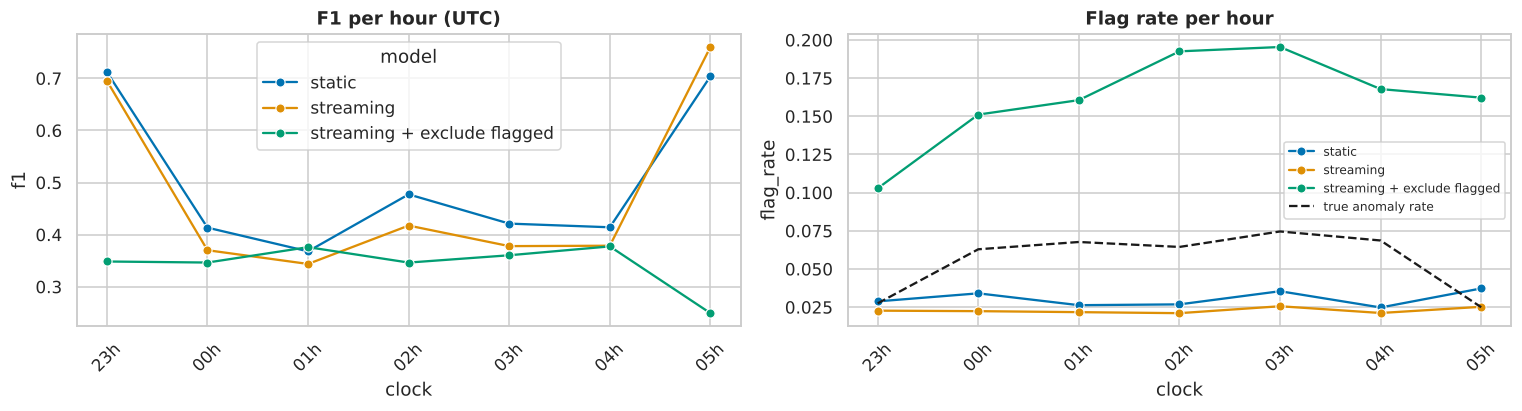

In [14]:
hour = ((vt.timestamps - T(20, 23).timestamp()) // 3600).astype(int)
rows = []
for h in sorted(set(hour)):
    m = hour == h
    for nm, fl in [("static", sta_f), ("streaming", on_f), ("streaming + exclude flagged", ox_f)]:
        rows.append(dict(hour=(23 + h) % 24, model=nm, f1=binary_f1(vt.y[m], fl[m]), flag_rate=fl[m].mean(), anomaly_rate=vt.y[m].mean()))
R = pd.DataFrame(rows); R["clock"] = [f"{h:02d}h" for h in R.hour]
order = [f"{(23 + h) % 24:02d}h" for h in sorted(set(hour))]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
sns.lineplot(R, x="clock", y="f1", hue="model", marker="o", ax=axes[0]); axes[0].set_title("F1 per hour (UTC)")
sns.lineplot(R, x="clock", y="flag_rate", hue="model", marker="o", ax=axes[1])
tru = R[R.model == "static"]; axes[1].plot(tru.clock, tru.anomaly_rate, "k--", label="true anomaly rate"); axes[1].legend(fontsize=8)
axes[1].set_title("Flag rate per hour")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

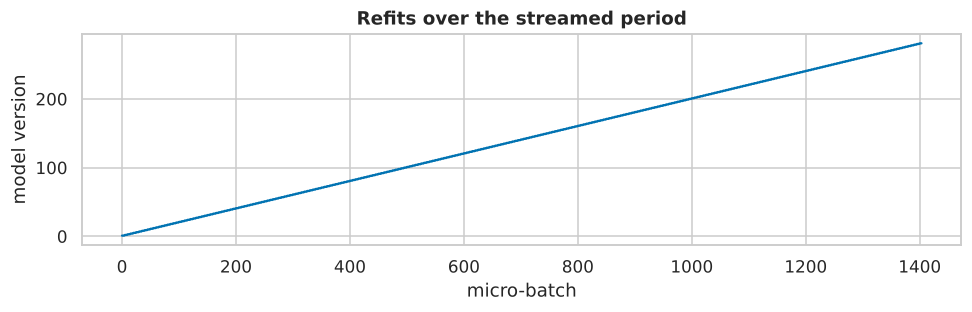

In [15]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot([r.details["model_version"] for r in out[::200]], color=PAL[0]); ax.set_xlabel("micro-batch"); ax.set_ylabel("model version")
ax.set_title("Refits over the streamed period"); plt.tight_layout(); plt.show()

## 7. Comparison with the Day 8 statistical baseline

`UnifiedStatisticalDetector.production()` (Z-score + IQR + CUSUM with the settings tuned in notebook 02),
fed every reading of every sensor chronologically from 22:00 so it has the same history as the forest.
Both are scored on the same test rows. Day 8 sees one raw number per sensor; the forest sees the whole
engineered vector.

In [16]:
full = ds.subset(ds.between(T(20, 22), T(21, 5, 30)))
vi = full.feature_index("value__last")
stat = UnifiedStatisticalDetector.production()
t0 = time.time(); sev = np.zeros(len(full)); sflag = np.zeros(len(full), bool)
for i in range(len(full)):
    r = stat.detect(full.entity_ids[i], float(full.X[i, vi]), datetime.fromtimestamp(full.timestamps[i], UTC), full.zones[i])
    sev[i], sflag[i] = r.severity_score, r.is_anomaly
print(f"Day 8 detector: {len(full)/(time.time()-t0):,.0f} readings/s")
in_te = full.timestamps >= T(21, 1, 30).timestamp()
in_va = (full.timestamps >= T(20, 23).timestamp()) & ~in_te & full.warm
stat_te = (sev[in_te], sflag[in_te])
# align the (warm-only) test rows of the forest with the Day 8 rows
key = lambda p: list(zip(p.entity_ids, np.round(p.timestamps, 3)))
pos = {k: i for i, k in enumerate(key(full.subset(in_te)))}
idx = np.array([pos[k] for k in key(te)])
sd_s, sd_f = stat_te[0][idx], stat_te[1][idx]
or_f = ft | sd_f
tbl = pd.concat({"Day 8 statistical": eval_part(te, sd_s, sd_f), "Isolation Forest (tuned, static)": Mt,
                 "Isolation Forest (streaming)": eval_part(te, on_s[is_test], on_f[is_test])}, names=["detector"])
tbl.loc[("IF OR Day 8", "ALL"), ["precision", "recall", "f1"]] = [precision_score(te.y, or_f), recall_score(te.y, or_f), f1_score(te.y, or_f)]
f1_tab = tbl["f1"].unstack("type")[TYPES + ["ALL"]]
f1_tab.round(3)

Day 8 detector: 26,312 readings/s


type,point,contextual,collective,ALL
detector,,,,
Day 8 statistical,0.396,0.152,0.050,0.384
"Isolation Forest (tuned, static)",0.799,0.059,0.100,0.451
Isolation Forest (streaming),0.815,0.026,0.064,0.413
IF OR Day 8,NaN,NaN,NaN,0.376


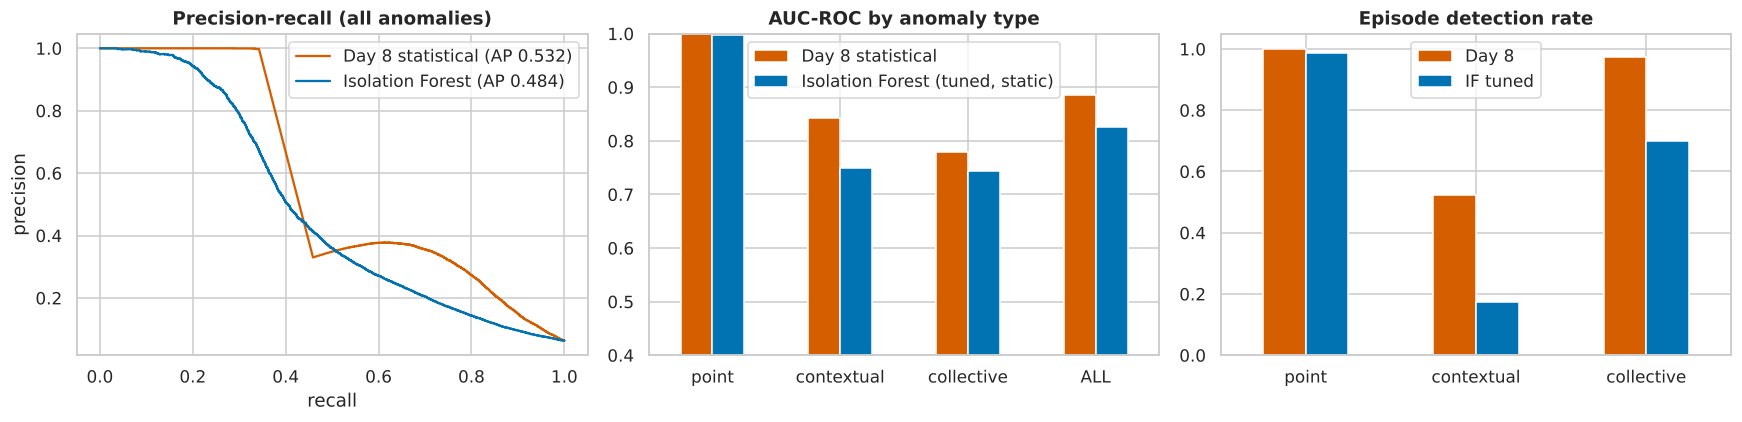

false-alarm incidents per sensor-day: Day 8 34.0 | IF tuned 118.5
median detection delay (s):


,Day 8,IF tuned
point,0.0,0.0
contextual,3.0,6.0
collective,13.0,13.0


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].set_title("Precision-recall (all anomalies)")
for nm, sc, c in [("Day 8 statistical", sd_s, PAL[3]), ("Isolation Forest", st, PAL[0])]:
    p, r, _ = precision_recall_curve(te.y, sc)
    axes[0].plot(r, p, color=c, label=f"{nm} (AP {average_precision_score(te.y, sc):.3f})")
axes[0].legend(); axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
auc = pd.DataFrame({nm: {typ: tbl.loc[(nm, typ), "auc_roc"] for typ in TYPES + ["ALL"]} for nm in ["Day 8 statistical", "Isolation Forest (tuned, static)"]})
auc.plot.bar(ax=axes[1], color=[PAL[3], PAL[0]]); axes[1].set_ylim(0.4, 1.0); axes[1].set_title("AUC-ROC by anomaly type"); axes[1].tick_params(axis="x", rotation=0)
ev_s, fa_s = event_table(te, sd_f)
det_cmp = pd.DataFrame({"Day 8": ev_s.detected, "IF tuned": ev_t.detected})
det_cmp.plot.bar(ax=axes[2], color=[PAL[3], PAL[0]]); axes[2].set_ylim(0, 1.05); axes[2].set_title("Episode detection rate"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(f"false-alarm incidents per sensor-day: Day 8 {fa_s:.1f} | IF tuned {fa_t:.1f}")
print("median detection delay (s):"); pd.DataFrame({"Day 8": ev_s.median_delay_s, "IF tuned": ev_t.median_delay_s}).round(1)

### Stacking preview (Day 12 builds the real meta-learner)

A logistic regression on the two scores, fitted on the **validation** period and applied to the test period,
with its decision threshold chosen on validation. This is only to see whether the two detectors are
complementary; the validation period was also used for tuning, so treat the number as indicative.

In [18]:
# Day 8 scores of the validation rows
pos_v = {k: i for i, k in enumerate(key(full.subset(in_va)))}
sev_va = sev[in_va][np.array([pos_v[k] for k in key(va)])]
s_va = det_t.score_batch(va.X)
Z_va, Z_te = np.c_[s_va, sev_va], np.c_[st, sd_s]
lr = LogisticRegression(class_weight="balanced").fit(Z_va, va.y)
p_va, p_te = lr.predict_proba(Z_va)[:, 1], lr.predict_proba(Z_te)[:, 1]
grid = np.linspace(0.05, 0.95, 91); thr = grid[np.argmax([binary_f1(va.y, p_va >= g) for g in grid])]
rows = [("Day 8 only", sd_s, sd_f), ("Isolation Forest only", st, ft), ("stacked (LogReg on both)", p_te, p_te >= thr)]
print("LogReg weights [IF, Day 8]:", lr.coef_.round(2), "| threshold", round(float(thr), 2))
pd.DataFrame([dict(model=n, precision=precision_score(te.y, f), recall=recall_score(te.y, f), f1=f1_score(te.y, f),
                   auc_pr=average_precision_score(te.y, s)) for n, s, f in rows]).set_index("model").round(3)

LogReg weights [IF, Day 8]: [[0.5  8.76]] | threshold 0.93


,precision,recall,f1,auc_pr
model,,,,
Day 8 only,0.330,0.459,0.384,0.532
Isolation Forest only,0.700,0.332,0.451,0.484
stacked (LogReg on both),0.998,0.327,0.493,0.567


## 8. Explainability with SHAP

`IsolationForestExplainer` wraps `shap.TreeExplainer`. SHAP values are in units of expected isolation path
length: **negative = shorter path = pushes the sample towards "anomaly"**. `get_top_features` returns the most
negative ones, which the dashboard will show in the alert detail panel (Day 20).

SHAP for 3,000 rows in 101.2s


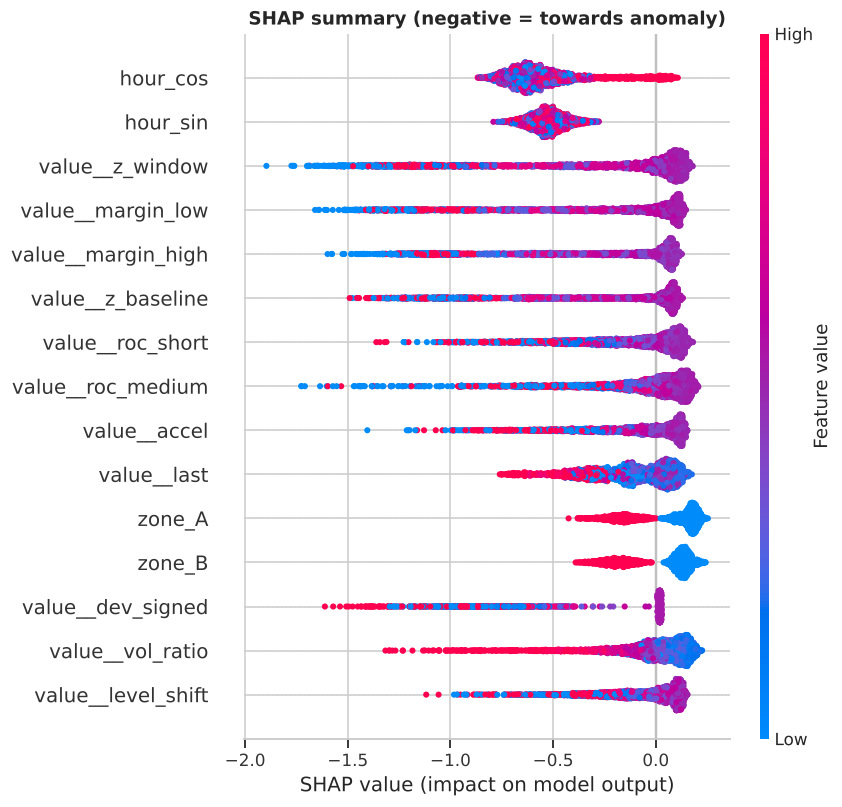

In [19]:
import shap
expl = IsolationForestExplainer(det_t)
rng = np.random.default_rng(1)
a_idx = rng.choice(np.where(te.y)[0], min(1500, int(te.y.sum())), replace=False)
n_idx = rng.choice(np.where(~te.y)[0], 1500, replace=False)
sel = np.sort(np.r_[a_idx, n_idx])
t0 = time.time(); sv = expl.compute_shap_values(te.X[sel]); print(f"SHAP for {len(sel):,} rows in {time.time()-t0:.1f}s")
Xs = det_t.impute(te.X[sel])
plt.figure(figsize=(9, 6))
shap.summary_plot(sv, Xs, feature_names=list(ds.feature_names), max_display=15, show=False)
plt.title("SHAP summary (negative = towards anomaly)"); plt.tight_layout(); plt.show()

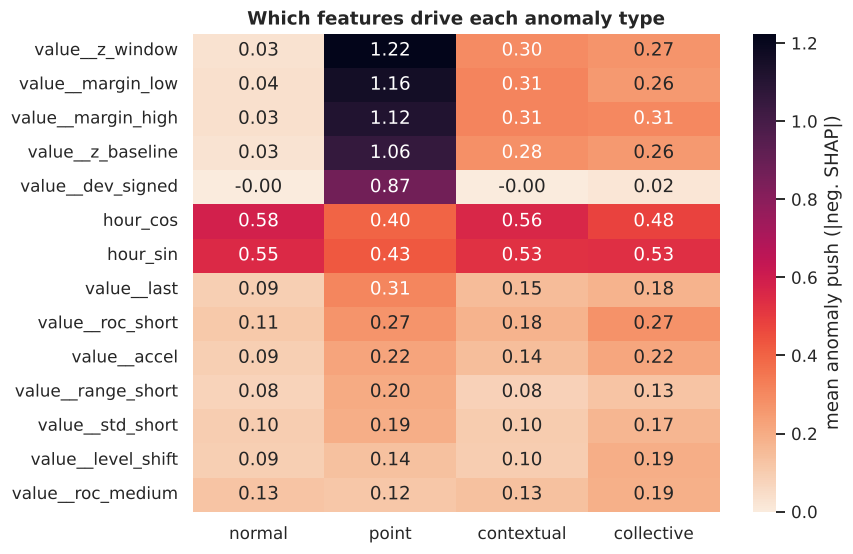

In [20]:
lab = np.where(te.y[sel], te.anomaly_type[sel].astype(str), "normal")
neg = np.minimum(sv, 0)                      # only the anomaly-pushing part
H = pd.DataFrame({l: -neg[lab == l].mean(0) for l in ["normal"] + TYPES}, index=ds.feature_names)
top = H.loc[H[TYPES].max(axis=1).sort_values(ascending=False).index[:14]]
plt.figure(figsize=(8, 5.2)); sns.heatmap(top, annot=True, fmt=".2f", cmap="rocket_r", cbar_kws=dict(label="mean anomaly push (|neg. SHAP|)"))
plt.title("Which features drive each anomaly type"); plt.tight_layout(); plt.show()

In [21]:
rows = []
for typ in TYPES:
    cand = np.where(te.anomaly_type == typ)[0]
    i = cand[np.argmax(st[cand])]                      # the most confidently detected example
    for rank, c in enumerate(expl.get_top_features(te.X[i], n=5), 1):
        rows.append(dict(type=typ, sensor=te.entity_ids[i], score=round(float(st[i]), 3), rank=rank,
                         feature=c.feature, shap=round(c.shap_value, 3), value=None if c.feature_value is None else round(c.feature_value, 3)))
pd.DataFrame(rows).set_index(["type", "sensor", "score", "rank"])

feature   shap   value
type       sensor       score rank                                   
point      wh2-B-hum-01 0.997 1       value__roc_short -1.146   0.348
                              2      value__dev_signed -1.047   0.565
                              3           value__accel -0.978   0.003
                              4     value__margin_high -0.906  -0.565
                              5      value__margin_low -0.900   1.565
contextual wh2-C-hum-01 0.967 1      value__roc_medium -1.197   0.017
                              2       value__roc_short -1.160   0.220
                              3       value__std_short -1.144  10.186
                              4       value__vol_ratio -0.931   2.091
                              5     value__level_shift -0.775   0.738
collective wh2-A-hum-01 0.964 1     value__margin_high -0.899  -0.160
                              2     value__level_shift -0.829   0.798
                              3        value__z_window -0.797   3.597
                              4      value__margin_low -0.784   1.160
                              5      value__z_baseline -0.754   3.963

### A caveat the SHAP plot exposes: calendar features

`hour_sin` / `hour_cos` push almost **every** test row towards "anomaly". The warm-up hour covers a
sliver of the clock, so the trees split on those features and any other time of day then looks
unfamiliar. Dropping the calendar encodings (hour, day-of-week, minute) from the forest is a cheap check:

In [22]:
cal = [n for n in ds.feature_names if n.split("_")[0] in ("hour", "dow", "minute")]
keep = [i for i, n in enumerate(ds.feature_names) if n not in cal]
d_nc = IsolationForestDetector([ds.feature_names[i] for i in keep], **BEST).fit(tr.X[:, keep])
s_nc, f_nc = d_nc.score_batch(te.X[:, keep]), d_nc.predict(te.X[:, keep])
rows = []
for nm, sc, fl in [(f"all {len(ds.feature_names)} features", st, ft), (f"without calendar ({len(keep)})", s_nc, f_nc)]:
    r = dict(model=nm, f1=f1_score(te.y, fl), auc_roc=roc_auc_score(te.y, sc), auc_pr=average_precision_score(te.y, sc), flag_rate=fl.mean())
    for typ in TYPES:
        m = ~te.y | (te.anomaly_type == typ); r[f"auc_{typ}"] = roc_auc_score(te.anomaly_type[m] == typ, sc[m])
    rows.append(r)
pd.DataFrame(rows).set_index("model").round(3)

,f1,auc_roc,auc_pr,flag_rate,auc_point,auc_contextual,auc_collective
model,,,,,,,
all 30 features,0.451,0.826,0.484,0.030,0.998,0.750,0.744
without calendar (24),0.443,0.836,0.510,0.022,0.999,0.765,0.762


## 9. Serialisation and the versioned model registry

In [23]:
registry = ModelRegistry(ROOT / "model_registry")
metrics = {"test_f1": float(Mt.loc["ALL", "f1"]), "test_precision": float(Mt.loc["ALL", "precision"]),
           "test_recall": float(Mt.loc["ALL", "recall"]), "test_auc_pr": float(Mt.loc["ALL", "auc_pr"]),
           "val_f1": float(result.best_f1), **{f"test_f1_{t}": float(Mt.loc[t, "f1"]) for t in TYPES}}
ver = registry.save("isolation_forest_warehouse", det_t, metrics=metrics, hyperparams=det_t.get_params(),
                    train_date=T(20, 23),
                    extra={"feature_names": list(online.feature_names), "note": "static detector fit on the 22:00-23:00 warm-up with tuned params; metrics are its test-period results"})
loaded = registry.get_latest_model("isolation_forest_warehouse")
same = np.allclose(loaded.model.score_batch(te.X[:2000]), det_t.score_batch(te.X[:2000]))
print("saved", ver.version, "| versions:", [v.version for v in registry.list_versions("isolation_forest_warehouse")][:3])
print("reloaded model scores identically:", same, "| model version inside:", loaded.model.model_version)
print(json.dumps({k: loaded.metadata[k] for k in ("model_type", "version", "train_date", "serializer", "size_bytes", "metrics")}, indent=2))

saved 20261122T103010717122Z | versions: ['20261122T103010717122Z', '20261122T100800462873Z', '20261122T094635192097Z']
reloaded model scores identically: True | model version inside: 1
{
  "model_type": "isolation_forest_warehouse",
  "version": "20261122T103010717122Z",
  "train_date": "2026-11-20T23:00:00+00:00",
  "serializer": "joblib",
  "size_bytes": 5870113,
  "metrics": {
    "test_f1": 0.4507146834973083,
    "test_precision": 0.7003846153846154,
    "test_recall": 0.33226895356263114,
    "test_auc_pr": 0.48398243199465585,
    "val_f1": 0.4784622510421491,
    "test_f1_point": 0.798580518844836,
    "test_f1_contextual": 0.059083507792509884,
    "test_f1_collective": 0.0997207818109294
  }
}


## 10. Throughput: why the streaming engine must micro-batch

In [24]:
x = te.X[:2000]; d = IsolationForestDetector(ds.feature_names, **BEST).fit(tr.X)
t0 = time.time(); [d.update("s", T(21, 2), x[i], learn=False) for i in range(100)]; single = (time.time() - t0) / 100
rows = [dict(mode="one event per call", per_event_ms=single * 1e3, events_per_s=1 / single)]
for b in (10, 50, 200, 1000):
    t0 = time.time(); n = 0
    for i in range(0, 2000 - b + 1, b):
        d.update_batch(["s"] * b, [T(21, 2)] * b, x[i:i + b], learn=False); n += b
    per = (time.time() - t0) / n; rows.append(dict(mode=f"micro-batch of {b}", per_event_ms=per * 1e3, events_per_s=1 / per))
pd.DataFrame(rows).set_index("mode").round(3)

,per_event_ms,events_per_s
mode,,
one event per call,15.945,62.715
micro-batch of 10,1.307,764.959
micro-batch of 50,0.265,3776.296
micro-batch of 200,0.080,12503.701
micro-batch of 1000,0.027,36975.722


## 11. Key findings

All numbers are from the untouched 4-hour test period (172 800 rows, 6.3 % anomalous, simulation seed 7).

**What works**
- **Point anomalies are essentially solved by the forest**: F1 0.80 (AUC-ROC 0.998), 99 % of episodes
  detected with a median delay of 0 s, versus F1 0.40 for the Day 8 statistical detector.
- **Tuning matters mostly through `contamination`** (fANOVA importance 0.71). The default 0.01 flags
  1.6 % of rows when 6.3 % are anomalous; the tuned 0.019 lifts validation F1 from 0.386 to 0.478 and test
  F1 from 0.369 to 0.451, with the biggest gain in collective-episode detection (38 % -> 70 %).
  Optuna's median pruner stopped 28 of 50 trials early (65 s in total).
- **The two detectors are complementary.** A logistic-regression stack of the two scores (fitted on validation) reaches
  F1 0.493 and AUC-PR 0.567, against 0.451 / 0.484 (forest) and 0.384 / 0.532 (Day 8). Indicative only: the validation
  period was also used for tuning. Day 12 builds the real meta-learner.
- **Explanations are usable**: the top-5 SHAP features for the most confident example of each type are sensible
  (rate-of-change and range deviation for the point spike, volatility for the contextual one, level-shift and
  z-scores for the collective drift).

**What does not work (yet)**
- **Contextual and collective anomalies are weak**: F1 0.06 and 0.10, AUC-ROC about 0.75. The 30 vectors describe
  *recent dynamics*; an off-hours reading that is individually plausible, or a slow drift, does not look isolated.
  This is the job of the LSTM models (Days 10-11). The Day 8 detector, with its hour-of-day buckets, is slightly better on
  contextual anomalies (F1 0.15) and the forest on collective ones (0.10 vs 0.05); both are poor.
- **False alarms are high**: about 118 false-alarm incidents per sensor-day for the tuned forest (22 default, 34 Day 8).
  Precision is 0.70 row-wise, but isolated false flags add up at 1 reading per second. Alert deduplication and the
  severity scorer (Day 12) are not optional.
- **The streaming refit did not beat the frozen model on this data**: F1 0.413 vs 0.451 (flag rate 2.3 % vs 3.0 %). The
  simulated sensors are close to stationary apart from the daily cycle, so there is little drift to adapt to. Keep the
  mechanism (it will matter on real, drifting sensors) but do not expect a gain from it here.
- **Keeping flagged vectors out of the reservoir is harmful** with a quantile-based boundary: each refit sees a truncated
  distribution and flags more, so the flag rate ran away from 10 % to 19 % within four hours (F1 0.352). I had built it
  that way first, measured it, and turned it off by default (`exclude_flagged=False`).
- **Calendar features hurt** when the warm-up covers a single hour (see the check above): removing them improves
  AUC-PR slightly at similar F1. Until at least a full day of warm-up data exists, leave them out of the forest's inputs.

**Operational notes**
- scikit-learn has a fixed cost of about 14 ms per call: scoring one event at a time gives only about 70 events/s; micro-batches of
  200 give about 9 000/s and 1 000 give about 30 000/s. The streaming engine (Day 15) must micro-batch.
- Streaming with a refit every 1 000 vectors sustained about 1 400 vectors/s including the refits (each about 0.5 s, blocking).
- SHAP costs about 30 ms per row: compute it on demand for an alert's detail view, not for every event.
- The data is simulated, with three injected anomaly types and a single ground-truth label per row. These numbers show how the
  method behaves on this generator, not how it will behave on real sensors.